Ce notebook présente le modèle XGBoost aprés un préprocessing strict commun 

In [1]:
#Importation du fichier pour l'entrainement du modèle
import pandas as pd
import numpy as np

df = pd.read_csv("../data/final_metropole/donnees_modeles.csv", dtype={"code_dept": str})

pas_variables = ["date_semaine", "date_cible", "annee", "annee_cible", "semaine", "jeu",
                 "TousAge_allergie_urgences", "cible", "pic", "moy4", "population"]
variables = [c for c in df.columns if c not in pas_variables]

#Séparation des jeux train, val, test
train = df[df["jeu"] == "train"]
val = df[df["jeu"] == "val"]
test = df[df["jeu"] == "test"]
train_val = df[df["jeu"] != "test"]

X_train, y_train = train[variables], train["cible"]
X_val, y_val = val[variables], val["cible"]
X_test, y_test = test[variables], test["cible"]
X_train_val, y_train_val = train_val[variables], train_val["cible"]

Définition des features, encodage du département et binarisation finale

Liste toutes les valeurs hebdomadaires des urgences pour un département, classées de la plus petite à la plus grande.
Le 90e percentile est la valeur située aux 90 % de cette liste.
Interprétation métier : 90 % du temps, le département connaît une activité normale ou modérée inférieure à ce seuil. En revanche, lorsque les urgences dépassent cette valeur, on entre dans les 10 % de semaines les plus tendues, ce qui caractérise statistiquement une situation d'alerte ou de pic épidémique.

In [2]:
#Calcul du 90e percentile d'alerte par département sur le Train (2021-2022)
seuils_par_dept = (
    train_val.groupby("code_dept")["cible"].quantile(0.90).to_dict()
)

# Fonction de binarisation locale directe
def binarise_par_dept(df_split, seuils_dict):
  temp = df_split.copy()
  # Association directe du seuil propre à chaque département
  seuil_serie = temp['code_dept'].map(seuils_dict)
  # Comparaison : 1 si la valeur future dépasse le seuil local, 0 sinon
  return (temp['cible'] >= seuil_serie).astype(int)


# Application sur tes trois splits
y_train_class = binarise_par_dept(train_val, seuils_par_dept)
y_test_class = binarise_par_dept(test, seuils_par_dept)

# Vérification rapide de la proportion d'alertes (doit être proche de 10% partout)
print(
    "Proportion d'alertes (90e percentile) - Train (2021-2023) :"
    f" {y_train_class.mean()*100:.1f}%"
)
print(
    "Proportion d'alertes (90e percentile) - Test (2024)         :"
    f" {y_test_class.mean()*100:.1f}%"
)

Proportion d'alertes (90e percentile) - Train (2021-2023) : 10.5%
Proportion d'alertes (90e percentile) - Test (2024)         : 6.5%


Preprocessing pour XGboost

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identification explicite des colonnes catégorielles et numériques
cat_cols = ['code_dept']
num_cols = [c for c in X_train.columns if c not in cat_cols]

# Construction du préprocesseur pour le xgb
preprocessor_xgb= ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
        remainder='passthrough'
)

# Application (Fit sur le Train uniquement, Transform sur Val et Test)
X_train_xgb = preprocessor_xgb.fit_transform(X_train_val)
X_test_xgb = preprocessor_xgb.transform(X_test)

print('\nDimensions après preprocessing SVC :')
print(f'X_train_xgb : {X_train_xgb.shape}')
print(f'X_test_xgb  : {X_test_xgb.shape}')


Dimensions après preprocessing SVC :
X_train_xgb : (14688, 153)
X_test_xgb  : (4992, 153)


Calcul des Baselines Naïve sur Train, Val et Test

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Initialisation de la baseline (prédit toujours la classe majoritaire '0')
baseline_clf = DummyClassifier(strategy='most_frequent', random_state=42)

# "Entraînement" (apprentissage de la proportion majoritaire sur le train)
baseline_clf.fit(X_train_xgb, y_train_class)

# Prédictions sur les splits de train et Test
y_pred_train_base = baseline_clf.predict(X_train_xgb)
y_pred_test_base = baseline_clf.predict(X_test_xgb)

# Évaluation sur la train
print("--- Baseline Classification : Train (2021-2023) ---")
print(classification_report(y_train_class, y_pred_train_base, zero_division=0))

# Évaluation sur le Test (2024)
print("\n--- Baseline Classification : Test (2024) ---")
print(classification_report(y_test_class, y_pred_test_base, zero_division=0))

--- Baseline Classification : Train (2021-2023) ---
              precision    recall  f1-score   support

           0       0.90      1.00      0.94     13152
           1       0.00      0.00      0.00      1536

    accuracy                           0.90     14688
   macro avg       0.45      0.50      0.47     14688
weighted avg       0.80      0.90      0.85     14688


--- Baseline Classification : Test (2024) ---
              precision    recall  f1-score   support

           0       0.94      1.00      0.97      4669
           1       0.00      0.00      0.00       323

    accuracy                           0.94      4992
   macro avg       0.47      0.50      0.48      4992
weighted avg       0.87      0.94      0.90      4992



Entraînement & Optimisation du Modèle et Validation Finale sur Test (2024)

In [5]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Calcul automatique du ratio pour gérer le déséquilibre des classes
nb_neg = (y_train_class == 0).sum()
nb_pos = (y_train_class == 1).sum()
ratio_poids = nb_neg / nb_pos
print(
    f"Ratio de pondération (scale_pos_weight) sur 2021-2023 : {ratio_poids:.2f}"
)

#Instanciation directe avec les meilleurs hyperparamètres retenus
best_xgb = XGBClassifier(
    objective="binary:logistic",
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.75,
    colsample_bytree=1.0,
    scale_pos_weight=ratio_poids,
    eval_metric="auc",
    random_state=42,
    n_jobs=-1,
)

# Entraînement sur tout le Train unifié (2021-2023)
best_xgb.fit(X_train_xgb, y_train_class)

# Évaluation sur le Train (2021-2023) pour contrôler le surapprentissage
y_pred_train = best_xgb.predict(X_train_xgb)
y_proba_train = best_xgb.predict_proba(X_train_xgb)[:, 1]

print("\n--- Rapport XGBoost Optimisé : Train (2021-2023) ---")
print(classification_report(y_train_class, y_pred_train, zero_division=0))
print(f"ROC-AUC Train : {roc_auc_score(y_train_class, y_proba_train):.4f}")

# Évaluation finale sur le Test isolé (2024)
y_pred_test = best_xgb.predict(X_test_xgb)
y_proba_test = best_xgb.predict_proba(X_test_xgb)[:, 1]

print("\n--- Rapport XGBoost Optimisé : Test Final (2024) ---")
print(classification_report(y_test_class, y_pred_test, zero_division=0))
print(f"ROC-AUC Test  : {roc_auc_score(y_test_class, y_proba_test):.4f}")

Ratio de pondération (scale_pos_weight) sur 2021-2023 : 8.56

--- Rapport XGBoost Optimisé : Train (2021-2023) ---
              precision    recall  f1-score   support

           0       0.99      0.79      0.88     13152
           1       0.34      0.90      0.49      1536

    accuracy                           0.80     14688
   macro avg       0.66      0.85      0.68     14688
weighted avg       0.92      0.80      0.84     14688

ROC-AUC Train : 0.9262

--- Rapport XGBoost Optimisé : Test Final (2024) ---
              precision    recall  f1-score   support

           0       0.97      0.79      0.87      4669
           1       0.18      0.68      0.29       323

    accuracy                           0.78      4992
   macro avg       0.58      0.74      0.58      4992
weighted avg       0.92      0.78      0.83      4992

ROC-AUC Test  : 0.7830


crosstab

In [7]:
# Matrice de confusion détaillée sous forme de crosstab
print("\n--- Matrice de confusion : Baseline (Test 2024) ---")
df_crosstab_base = pd.crosstab(
    y_test_class,
    y_pred_test_base,
    rownames=["Réalité (Pic=1)"],
    colnames=["Prédiction Baseline"],
    margins=True,
    margins_name="Total",
)
print(df_crosstab_base)

print("\n--- Matrice de confusion : XGBoost Optimisé (Test 2024) ---")
df_crosstab_xgb = pd.crosstab(
    y_test_class,
    y_pred_test,
    rownames=["Réalité (Pic=1)"],
    colnames=["Prédiction XGB"],
    margins=True,
    margins_name="Total",
)
print(df_crosstab_xgb)


--- Matrice de confusion : Baseline (Test 2024) ---
Prédiction Baseline     0  Total
Réalité (Pic=1)                 
0                    4669   4669
1                     323    323
Total                4992   4992

--- Matrice de confusion : XGBoost Optimisé (Test 2024) ---
Prédiction XGB      0     1  Total
Réalité (Pic=1)                   
0                3674   995   4669
1                 102   221    323
Total            3776  1216   4992


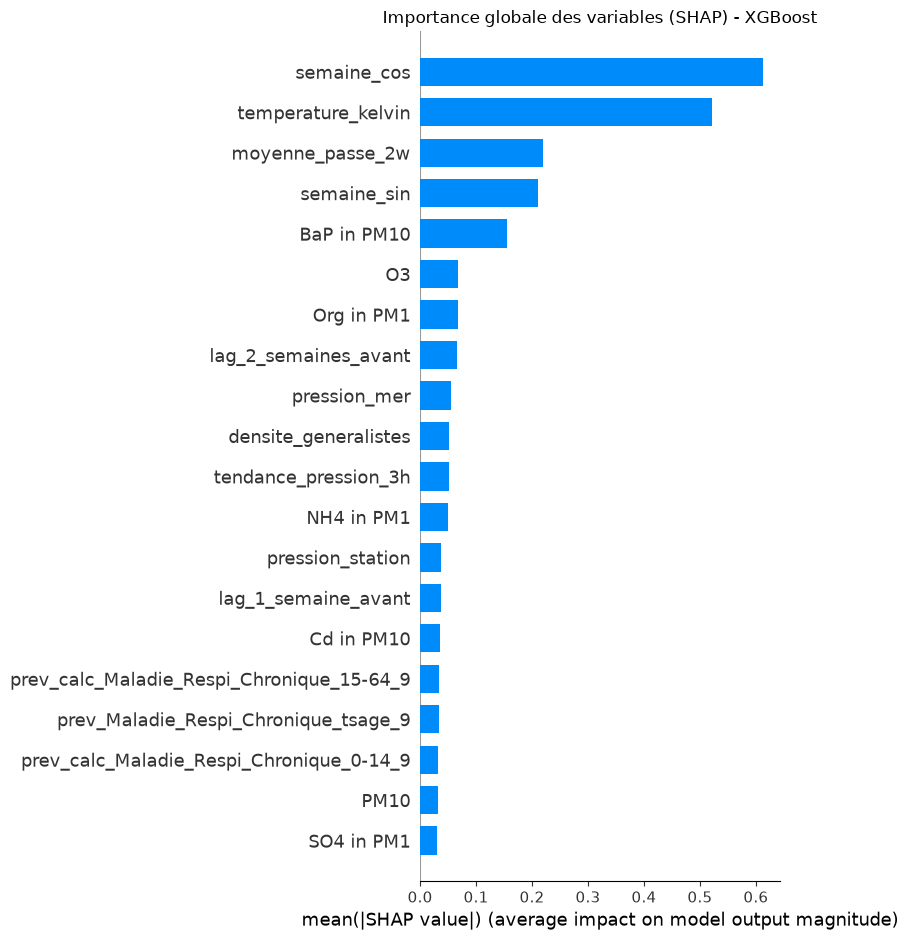

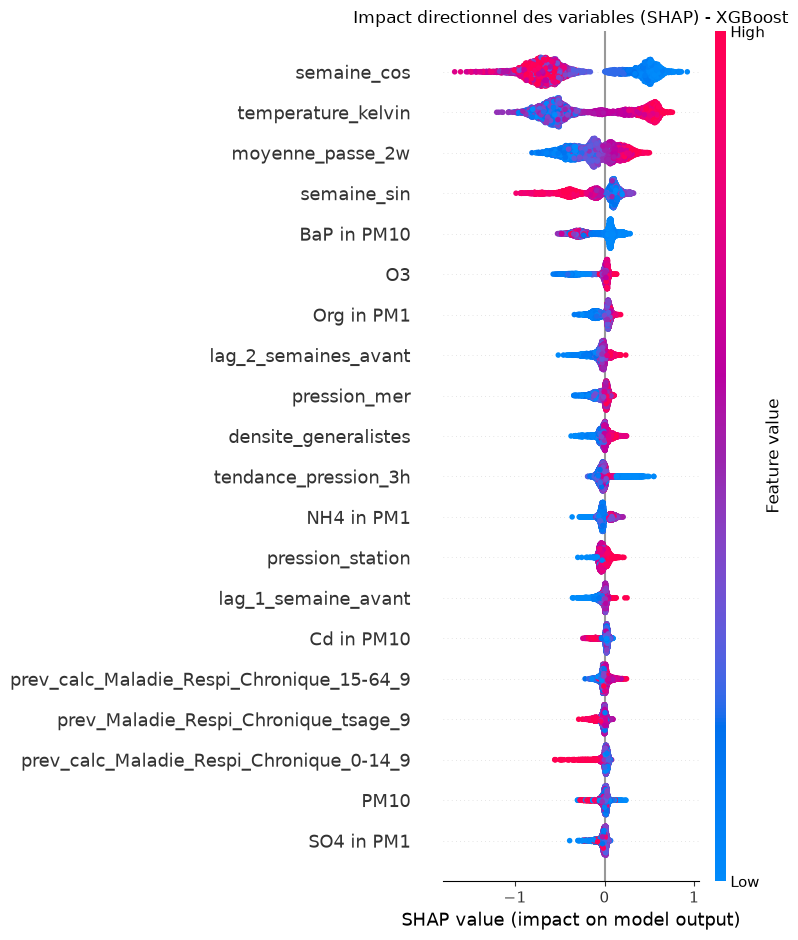

In [8]:
import matplotlib.pyplot as plt
import shap

# Conversion en matrice dense si OneHotEncoder a renvoyé une matrice sparse
X_test_dense = (
    X_test_xgb.toarray() if hasattr(X_test_xgb, "toarray") else X_test_xgb
)

# Nettoyage des préfixes 'cat__' et 'remainder__' pour des graphiques lisibles
noms_colonnes = [
    col.split("__")[-1] for col in preprocessor_xgb.get_feature_names_out()
]
X_test_xgb_df = pd.DataFrame(X_test_dense, columns=noms_colonnes)

# Calcul rapide des valeurs SHAP via TreeExplainer sur tout le Test (2024)
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer(X_test_xgb_df)

# Importance globale des facteurs de risque (Bar plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_xgb_df, plot_type="bar", show=False)
plt.title("Importance globale des variables (SHAP) - XGBoost")
plt.tight_layout()
plt.show()

# Graphique d'impact directionnel (Beeswarm plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_xgb_df, show=False)
plt.title("Impact directionnel des variables (SHAP) - XGBoost")
plt.tight_layout()
plt.show()


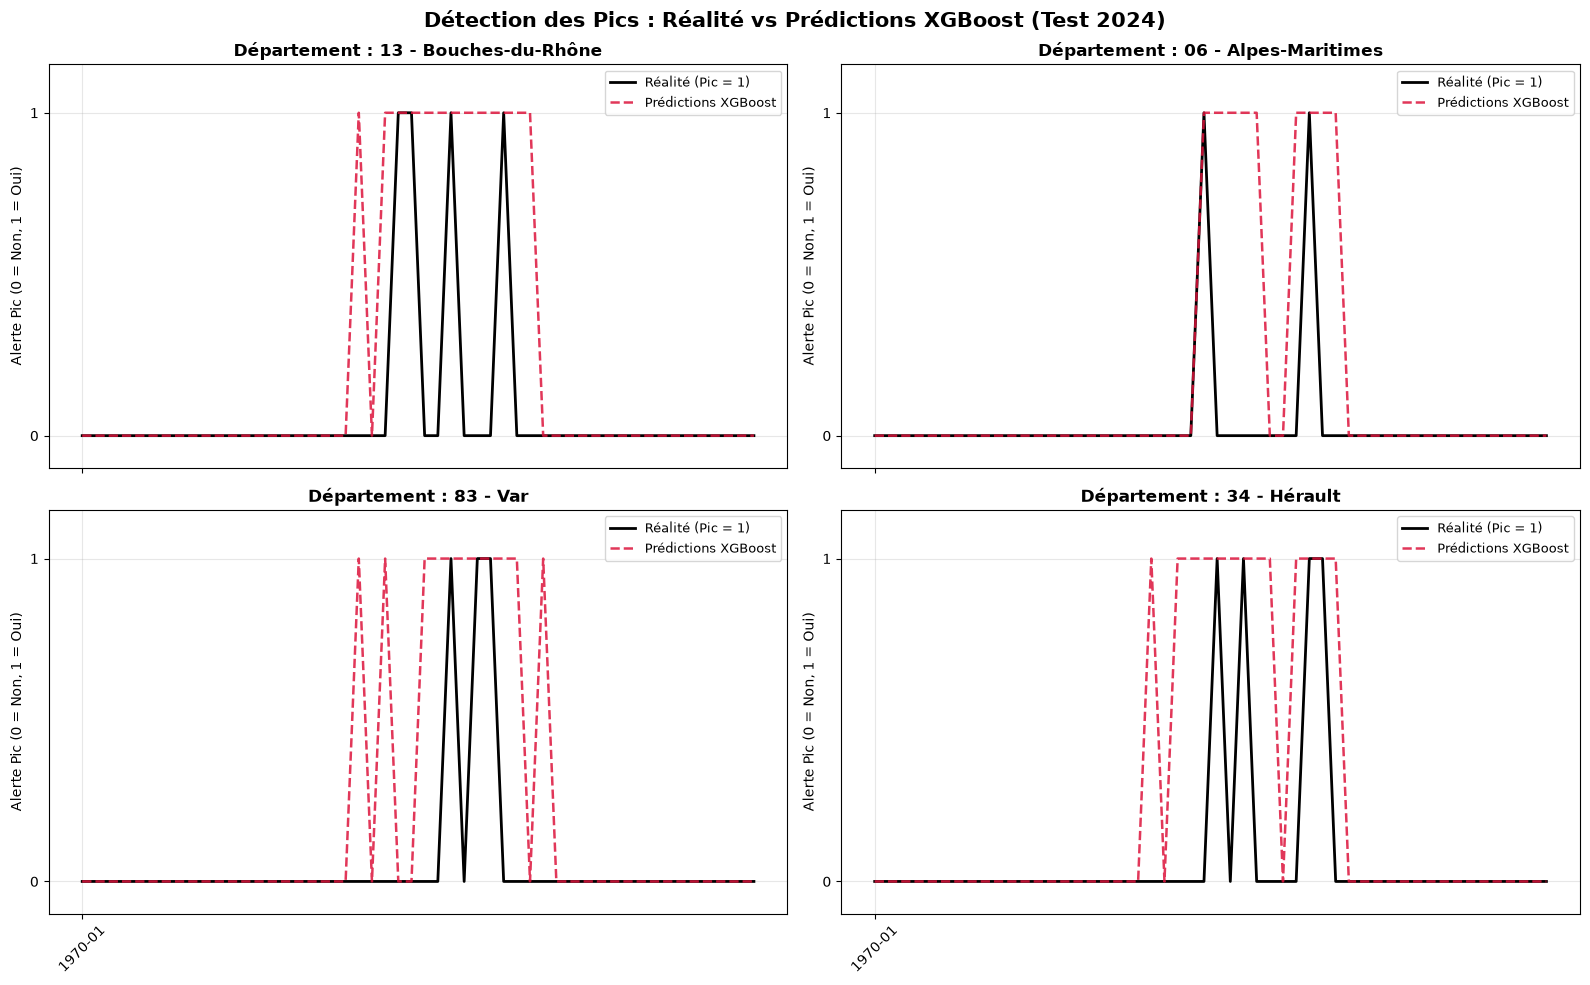

In [12]:
import matplotlib.dates as mdates

# Copie et préparation des données de test (2024)
df_plot = test.copy()
df_plot['y_reel'] = y_test_class.values
df_plot['y_pred'] = y_pred_test
#df_plot['date_semaine'] = pd.to_datetime(
 #   df_plot['date_semaine'])

liste_depts = ['13', '06', '83', '34']
noms_depts = {
    '13': '13 - Bouches-du-Rhône',
    '06': '06 - Alpes-Maritimes',
    '83': '83 - Var',
    '34': '34 - Hérault',
}

# Filtrer pour ne garder que ces 4 départements
df_plot_4depts = df_plot[df_plot['code_dept'].isin(liste_depts)]

# Création de la figure en grille (2x2)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 10), sharex=True)
axes = axes.flatten()

for i, dept in enumerate(liste_depts):
  ax = axes[i]
  df_dept = df_plot_4depts[
      df_plot_4depts['code_dept'] == dept
  ].sort_values('date_semaine')

  # Tracé des pics réels vs prédits
  ax.plot(
      df_dept['date_semaine'],
      df_dept['y_reel'],
      label='Réalité (Pic = 1)',
      color='black',
      linewidth=2,
  )
  ax.plot(
      df_dept['date_semaine'],
      df_dept['y_pred'],
      label='Prédictions XGBoost',
      color='crimson',
      linestyle='--',
      linewidth=1.8,
      alpha=0.85,
  )

  ax.set_title(
      f'Département : {noms_depts[dept]}', fontsize=12, fontweight='bold'
  )
  ax.set_ylabel('Alerte Pic (0 = Non, 1 = Oui)', fontsize=10)
  ax.set_ylim(-0.1, 1.15)
  ax.set_yticks([0, 1])
  ax.legend(loc='upper right', fontsize=9)
  ax.grid(True, alpha=0.3)

  ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
  ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
  ax.tick_params(axis='x', rotation=45)

plt.suptitle(
    'Détection des Pics : Réalité vs Prédictions XGBoost (Test 2024)',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

In [13]:
#export modele entrainer pour le Streamlit
import joblib

joblib.dump(best_xgb, "../streamlit/modeles/xgb_clffinal.pkl")

['../streamlit/modeles/xgb_clffinal.pkl']